In [1]:
import wandb
import pandas as pd
api = wandb.Api()

In [44]:
import matplotlib.pyplot as plt
import numpy as np

def runs_on_task_bar_chart(runs_dict):
    df_list = []
    for group_name, runs in runs_dict.items():
        for run in runs:
            df_list.append(
                run.summary._json_dict | {
                    "name": run.name,
                    "id": run.id,
                    "tags": run.tags,
                    "group": group_name,
                    "downstream_task": run.config.get("dataset", {}).get("dataset_name"),
                    "orients_promoters": run.config.get("canonicalization", {}).get("orient_promoters", False)
                }
            )

    df = pd.DataFrame(df_list)
    groups = sorted(df["group"].dropna().unique())
    tasks = sorted(df["downstream_task"].dropna().unique())
    if "hg38" in tasks:
        tasks.remove("hg38")

    x = np.arange(len(tasks))
    width = 0.8 / len(groups)

    fig, ax = plt.subplots(figsize=(14, 5))

    def get_tasks_metric(tasks: pd.DataFrame) -> pd.Series:
        if "val/mcc" in tasks.columns and tasks["val/mcc"].notna().any():
            return tasks["val/mcc"]
        elif "val/auroc" in tasks.columns and tasks["val/auroc"].notna().any():
            return tasks["val/auroc"]
        elif "val/accuracy" in tasks.columns and tasks["val/accuracy"].notna().any():
            return tasks["val/accuracy"]
        elif "val/loss" in tasks.columns and tasks["val/loss"].notna().any():
            return tasks["val/loss"]
        else:
            raise RuntimeError("Metric not found")

    bar_containers = []
    for i, group in enumerate(groups):
        vals = []
        for t in tasks:
            vals.append(get_tasks_metric(df[(df["group"] == group) & (df["downstream_task"] == t)]).mean())

        # Replace NaNs with 0 for plotting so bars render cleanly
        vals = np.nan_to_num(vals, nan=0.0)
        bars = ax.bar(x + i * width - width * len(groups) / 2, vals, width, label=group)
        bar_containers.append(bars)

    # Add labels on each bar (showing three decimals)
    for container in bar_containers:
        ax.bar_label(container, fmt="%.2f", padding=3)

    ax.set_xticks(x)
    ax.set_xticklabels(tasks, rotation=45, ha="right")
    ax.set_title("Metricas por task y grupo")
    ax.legend()

    plt.tight_layout()
    plt.show()

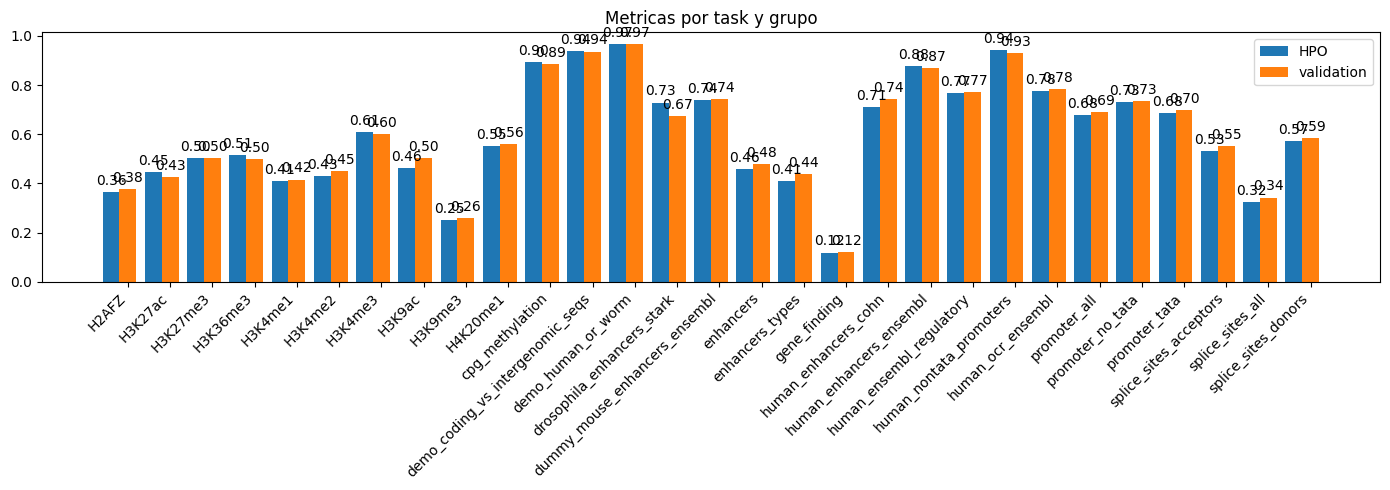

In [45]:
hpo_runs = api.runs("pipe-verri-gh/Canonicalization", filters={
    "tags": {"$in": ["trial_11"]}
})
validation_runs = api.runs("pipe-verri-gh/Canonicalization", filters={
    "group": "canonicalized"
})

runs_on_task_bar_chart({"HPO": hpo_runs, "validation": validation_runs})